# Aperture calculations

In the previous notebook we saved the shared aperture definitions and the line's
placements and settings as `aperture_model.json`. Here we reload the lattice and the model.

The aperture model gives the available transverse cross-section at any longitudinal position `s`. Once the model is combined with optics and beam parameters, we can ask questions such as:

- What does the aperture cross-section look like here?
- What beam envelope corresponds to a given number of sigmas?
- What is the limiting aperture, expressed as `n1`, at an element or at selected `s` positions?
- What are the horizontal, vertical, and diagonal aperture margins?
- How can the interpolated aperture be converted back into ordinary `LimitPolygon` elements?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xtrack as xt

# Load the lattice + the model
env = xt.load("toy_ring.json")
env.aperture.from_json("aperture_model.json")

ring = env["ring"]

model = ring.aperture
model.build_model()
twiss = ring.twiss()

print(model)

Loading line from dict:   0%|          | 0/84 [00:00<?, ?it/s]

Done loading line from dict.           
Done loading line from dict.           


Building cross-sections:   0%|          | 0/244 [00:00<?, ?it/s]

<LineAperture: 114 pipe positions>


## Cross-sections (profile interpolation)

The lowest-level useful query is the interpolated aperture cross-section. We can sample at arbitrary `s` positions with `get_cross_sections_at_s`, or across an element with `get_cross_sections_at_element`.

For axis intersections without polygons, use `get_extents_at_s` or `get_extents_at_element`.

In [2]:
sample_s = np.arange(10.36, 10.65, 0.05)

# Interpolate at explicit s-positions
sections = model.get_cross_sections_at_s(sample_s, extents=True)
#sections = model.get_cross_sections_at_element("||drift_5", resolution=0.05, extents=True)

# If only extents are of interest, we can use the convenience function:
#extents = model.get_extents_at_s(sample_s)
#mb_extents = model.get_extents_at_element("||drift_5", resolution=0.25)

sections.cols["s cross_section min_x max_x min_y max_y pose"].show(maxwidth="full")
#extents.cols["s min_x max_x min_y max_y pose"].show(maxwidth="full")

index                             s   cross_section         min_x         max_x         min_y         max_y          pose
0                             10.36 <array(128, 2)>    -0.0519548     0.0519548    -0.0519548     0.0519548 <array(4, 4)>
1                             10.41 <array(128, 2)>    -0.0524953      0.052492    -0.0488538     0.0488542 <array(4, 4)>
2                             10.46 <array(128, 2)>    -0.0530309     0.0530235    -0.0457471     0.0457478 <array(4, 4)>
3                             10.51 <array(128, 2)>    -0.0535613     0.0535491    -0.0426346     0.0426354 <array(4, 4)>
4                             10.56 <array(128, 2)>    -0.0540863     0.0540686    -0.0395161     0.0395168 <array(4, 4)>
5                             10.61 <array(128, 2)>     -0.054606     0.0545818    -0.0363915     0.0363918 <array(4, 4)>
Interpolating profiles: 100%

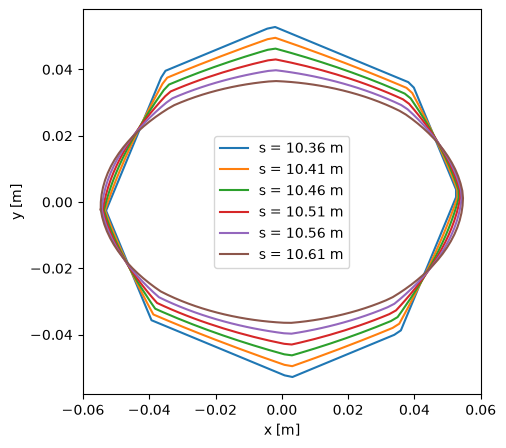

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
for row in sections.rows:
    polygon = row.cross_section
    ax.plot(polygon[:, 0], polygon[:, 1], label=f"s = {row.s:.2f} m")
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend();

## Beam envelope calculation

To compute the beam envelopes and aperture sigmas the aperture model is combined with:

- local optics and closed-orbit values from Twiss,
- user beam and tolerance parameters in `halo_params`,
- mechanical tolerances attached to the active aperture profile position.

The halo parameters currently configured on the aperture object are:

In [4]:
model.halo_params

{'nemitt_x': 1e-06,
 'nemitt_y': 1e-06,
 'delta_rms': 0.0,
 'tol_co': 0.0,
 'tol_disp': 0.0,
 'tol_disp_ref': 1.0,
 'tol_disp_ref_beta': 1.0,
 'tol_beta_beating': 1.0,
 'halo_x': 1.0,
 'halo_y': 1.0,
 'halo_r': 1.0,
 'halo_primary': 1.0}

This is what each of the values means:

- `nemitt_x` ($\varepsilon_{x,\mathrm{n}}$) and `nemitt_y` ($\varepsilon_{y,\mathrm{n}}$): normalised emittances;
- `delta_rms` ($\delta_\mathrm{rms}$): RMS relative momentum spread;
- `tol_co` ($r_\mathrm{co}$): closed-orbit uncertainty margin;
- `tol_disp` ($f_D$): dispersion-tolerance scaling factor;
- `tol_disp_ref` ($D_\mathrm{ref}$): reference dispersion error;
- `tol_disp_ref_beta` ($\beta_{D,\mathrm{ref}}$): reference beta for dispersion scaling;
- `tol_beta_beating` ($f_\beta$): beta-beating scaling factor;
- `halo_x`, `halo_y`, `halo_r`, `halo_primary`: define the reference beam racetrack shape through
  $h_x = \mathrm{halo\_x}/\mathrm{halo\_primary}$,
  $h_y = \mathrm{halo\_y}/\mathrm{halo\_primary}$, and
  $h_r = \mathrm{halo\_r}/\mathrm{halo\_primary}$.

For a one-betatron-sigma beam, the optical sizes are

$$
\sigma_x = \sqrt{\frac{\varepsilon_{x,\mathrm{n}}}{\gamma_r\beta_r}\,\beta_x}\; f_\beta,
\qquad
\sigma_y = \sqrt{\frac{\varepsilon_{y,\mathrm{n}}}{\gamma_r\beta_r}\,\beta_y}\; f_\beta.
$$

The envelope calculation builds a racetrack-shaped beam from these one-sigma sizes, scales it by the requested number of sigmas, and adds margins from closed orbit, dispersion tolerance, and aperture-profile tolerances. The dispersion tolerance margins used internally scale like

$$
\Delta x_D = f_\beta f_D D_\mathrm{ref}
\sqrt{\frac{\beta_x}{\beta_{D,\mathrm{ref}}}}\,\delta_\mathrm{rms},
\qquad
\Delta y_D = f_\beta f_D D_\mathrm{ref}
\sqrt{\frac{\beta_y}{\beta_{D,\mathrm{ref}}}}\,\delta_\mathrm{rms}.
$$

Finally, the closed orbit tolerance and the dispersive orbit shift $(D_x\delta_\mathrm{rms}, D_y\delta_\mathrm{rms})$ are added.

In [5]:
model.halo_params.update(
    delta_rms=1.0e-4,
    tol_co=1.0e-3,
    tol_disp=1.0,
)
model.halo_params

{'nemitt_x': 1e-06,
 'nemitt_y': 1e-06,
 'delta_rms': 0.0001,
 'tol_co': 0.001,
 'tol_disp': 1.0,
 'tol_disp_ref': 1.0,
 'tol_disp_ref_beta': 1.0,
 'tol_beta_beating': 1.0,
 'halo_x': 1.0,
 'halo_y': 1.0,
 'halo_r': 1.0,
 'halo_primary': 1.0}

## Calculating the beam envelopes

The most straightforward way of obtaining the beam envelopes is through `get_envelope_at_s` or `get_envelope_at_element`:

In [6]:
mb_envelopes, mb_twiss = model.get_envelope_at_element(
    "mb.0",
    sigmas=6.0,
    resolution=0.1,
    envelopes_num_points=128,
    polygons=True,
    extents=True,
)
mb_envelopes.show(maxwidth="full")

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


index                             s   cross_section         min_x         max_x         min_y         max_y
0                           8.54828 <array(128, 2)>    -0.0225364     0.0225364    -0.0110053     0.0110053
1                           8.65769 <array(128, 2)>    -0.0223769     0.0223769     -0.011321      0.011321
2                           8.76709 <array(128, 2)>    -0.0222057     0.0222057    -0.0116372     0.0116372
3                           8.87649 <array(128, 2)>    -0.0220229     0.0220229     -0.011954      0.011954
4                            8.9859 <array(128, 2)>    -0.0218286     0.0218287    -0.0122713     0.0122713
5                            9.0953 <array(128, 2)>     -0.021623      0.021623     -0.012589      0.012589
6                            9.2047 <array(128, 2)>    -0.0214061     0.0214061    -0.0129071     0.0129071
7                            9.3141 <array(128, 2)>    -0.0211781     0.0211781    -0.0132256     0.0132256
8                          

We can combine the cross-sections with the beam envelopes to plot them in relation
to each other through a section of the machine.

In fact, a function `plot_transverse(sigmas=...)` is already provided as part of
the module. Parameter `middle="beam"` (default) keeps the beam reference at the origin;
`middle="aperture"` recentres each cross-section on the aperture.

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing beam envelopes: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

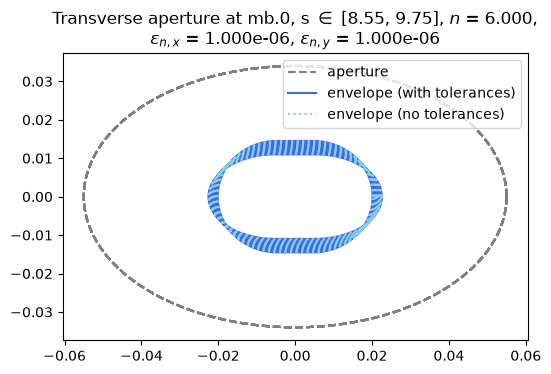

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
model.plot_transverse("mb.0", resolution=0.1, sigmas=6.0, middle="beam", ax=ax);

The same helper also accepts explicit `s_positions`, which is useful when the points of interest are not tied to a single element.

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing beam envelopes: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

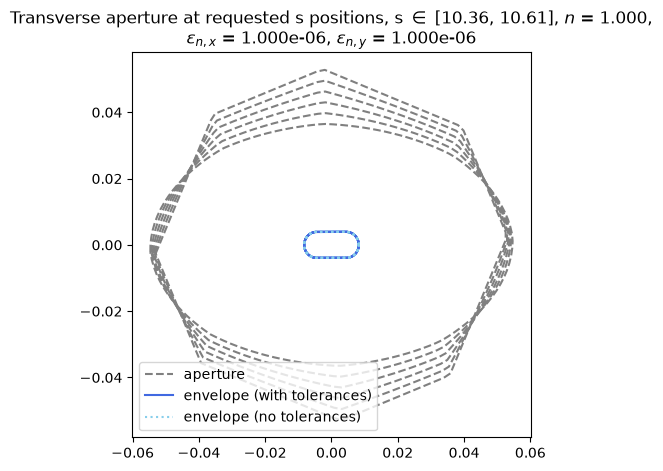

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
model.plot_transverse(s_positions=sample_s, sigmas=1.0, middle="beam", ax=ax);

# Computing the maximum aperture sigmas ($n_1$)

In the above plotting function, the `sigmas` parameter can be omitted, in which case the beam
envelope will be displayed at each local $n_1$, and the minimum value will be given as well:

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 100%

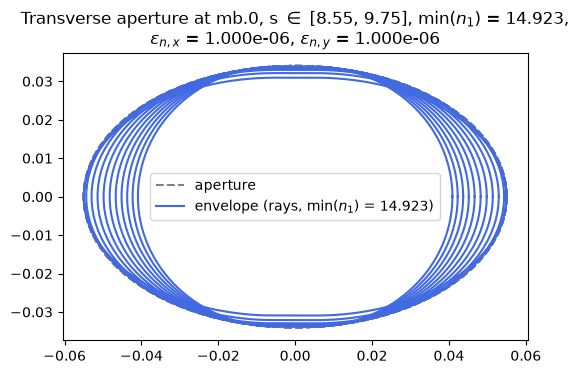

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
model.plot_transverse("mb.0", resolution=0.1, sigmas=None, method="rays", middle="beam", ax=ax);

Like with all of the plotting functions so far, the same data can be obtained manually in
the form of a table.

The function `get_aperture_sigmas_at_element` and `get_aperture_sigmas_at_s` serve this purpose.
We can additionally request `output_cross_sections=True` and `output_max_envelopes=True`
to get the aperture polygons in `cross_section` and the limiting-envelope polygons in
`envelope` (at the extra computation cost), alongside the local `n1` values.

In [10]:
n1_mb, _ = model.get_aperture_sigmas_at_element(
    "mb.0",
    resolution=0.1,
    method="rays",  # default
    envelopes_num_points=128,
    output_cross_sections=True,
    output_max_envelopes=True,
)
n1_mb.show(maxwidth="full")

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


index                             s            n1   cross_section        envelope
0                           8.54828       18.4154 <array(128, 2)> <array(128, 2)>
1                           8.65769        18.568 <array(128, 2)> <array(128, 2)>
2                           8.76709       18.4995 <array(128, 2)> <array(128, 2)>
3                           8.87649       18.1334 <array(128, 2)> <array(128, 2)>
4                            8.9859        17.705 <array(128, 2)> <array(128, 2)>
5                            9.0953       17.2753 <array(128, 2)> <array(128, 2)>
6                            9.2047       16.8412 <array(128, 2)> <array(128, 2)>
7                            9.3141       16.4155 <array(128, 2)> <array(128, 2)>
8                           9.42351       16.0122 <array(128, 2)> <array(128, 2)>
9                           9.53291       15.6299 <array(128, 2)> <array(128, 2)>
10                          9.64231       15.2672 <array(128, 2)> <array(128, 2)>
11             

For explicit `s` positions, use `get_aperture_sigmas_at_s` instead:

In [11]:
n1_at_s, n1_twiss = model.get_aperture_sigmas_at_s(
    sample_s,
    method="rays",  # default
    num_rays=32,
    output_cross_sections=True,
    output_max_envelopes=True,
)
n1_at_s.show(maxwidth='full')

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


index                             s            n1   cross_section       envelope
0                             10.36       18.8441 <array(128, 2)> <array(36, 2)>
1                             10.41       18.2403 <array(128, 2)> <array(36, 2)>
2                             10.46       17.3797 <array(128, 2)> <array(36, 2)>
3                             10.51       16.3833 <array(128, 2)> <array(36, 2)>
4                             10.56       15.3763 <array(128, 2)> <array(36, 2)>
5                             10.61       14.3583 <array(128, 2)> <array(36, 2)>
Computing sigmas: 100%

When a Twiss table has already been sampled, use `get_aperture_sigmas_for_twiss` to avoid recomputing optics.

In [12]:
n1_from_existing_twiss = model.get_aperture_sigmas_for_twiss(
    sliced_twiss=n1_twiss,
    method="rays",
    num_rays=32,
)
n1_from_existing_twiss


Computing sigmas: 100%

Table: 6 rows, 3 cols
index                             s            n1
0                             10.36       18.8441
1                             10.41       18.2403
2                             10.46       17.3797
3                             10.51       16.3833
4                             10.56       15.3763
5                             10.61       14.3583

## Horizontal, vertical, and diagonal sigmas

`get_hvd_aperture_sigmas_...` return a table with limiting sigma in three direction families:

- horizontal,
- vertical,
- diagonal at 45 degrees.

This provides more information than `n1`, which does not necessarily help with the directionality.

In [13]:
hvd_table, hvd_twiss = model.get_hvd_aperture_sigmas_at_s(sample_s)
hvd_table

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 100%

Table: 6 rows, 6 cols
index                             s n1_horizontal   n1_vertical   n1_diagonal   cross_section
0                             10.36       20.6243       20.5285       20.0318 <array(128, 2)>
1                             10.41       20.8329       19.2985        19.628 <array(128, 2)>
2                             10.46       21.0383       18.0738       19.1253 <array(128, 2)>
3                             10.51       21.2403       16.8544       18.5155 <array(128, 2)>
4                             10.56       21.4391       15.6402       17.6807 <array(128, 2)>
5                             10.61       21.6343       14.4313       16.8314 <array(128, 2)>

In [14]:
hvd_mb, _ = model.get_hvd_aperture_sigmas_at_element("mb.0", resolution=0.25)
hvd_mb

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 25%

Table: 4 rows, 6 cols
index                             s n1_horizontal   n1_vertical   n1_diagonal   cross_section
0                           8.54828       18.4154       20.2188       19.2161 <array(128, 2)>
1                           8.94943       19.0444       18.0991            18 <array(128, 2)>
2                           9.35057       19.8821       16.3712       17.1779 <array(128, 2)>
3                           9.75172        20.967       14.9375       16.6965 <array(128, 2)>

Computing sigmas: 100%

## Longitudinal extent plots

The function `plot_extents` gives a longitudinal view of the envelope and aperture limitations
in both planes. The parameter `sigmas` can be specified to display a particular envelope size,
otherwise it uses the minimum `n1` over the requested `s_positions`.

(Note, we already have all the ingredients to reproduce this plot: `get_extents_at_s` and
`get_envelope_at_s` + if $n_1$ is desired, `get_aperture_sigmas_at_s`).

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

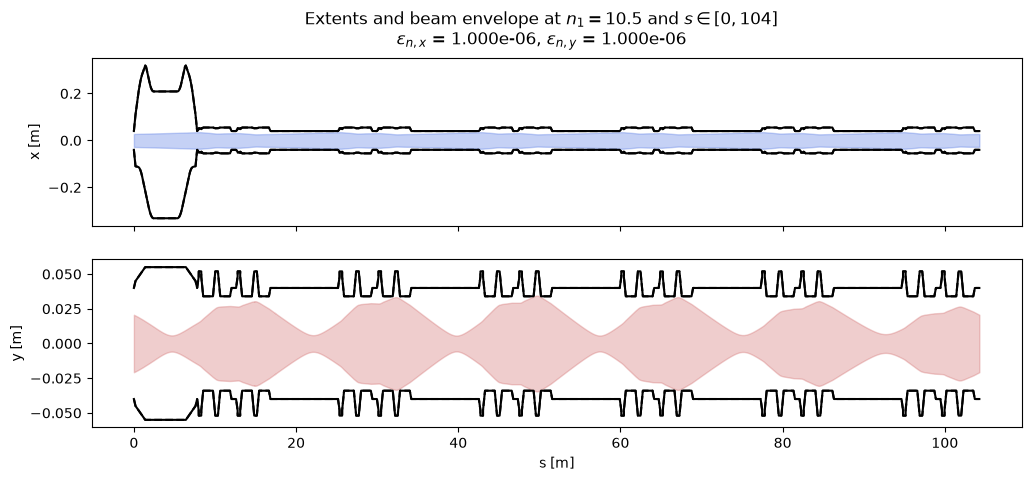

In [15]:
s_sample = model.get_s_around_transitions(resolution=0.1)
model.plot_extents(s_positions=s_sample)
plt.gcf().set_figwidth(12);

## Converting sampled aperture to `LimitPolygon` elements

The function `get_limit_elements_at_s` converts interpolated cross-sections at selected positions into ordinary Xtrack limit elements. This is useful when a calculation needs a conventional element representation rather than the aperture-model object.

In [16]:
limit_elements = model.get_limit_elements_at_s(sample_s[:2])

for s, element in limit_elements.items():
    print(f"s = {s:.3f} m -> {element}")


s = 10.360 m -> LimitPolygon(x_vertices=[-0.05303722, -0.05205868, -0.05108015, -0.05010161, -0.04912308,
       -0.04814454, -0.04716601, -0.04618747, -0.04520894, -0.0442304 ,
       -0.04325187, -0.04227333, -0.0412948 , -0.04031626, -0.03933773,
       -0.03835919, -0.03738066, -0.03640212, -0.03509602, -0.03273363,
       -0.03037123, -0.02800884, -0.02564645, -0.02328406, -0.02092167,
       -0.01855927, -0.01619688, -0.01383449, -0.0114721 , -0.0091097 ,
       -0.00674731, -0.00438492, -0.00202253,  0.00033986,  0.00270226,
        0.00506465,  0.00742704,  0.00978943,  0.01215183,  0.01451422,
        0.01687661,  0.019239  ,  0.02160139,  0.02396379,  0.02632618,
        0.02868857,  0.03105096,  0.03341336,  0.03577575,  0.03813814,
        0.039827  ,  0.04080553,  0.04178407,  0.0427626 ,  0.04374114,
        0.04471967,  0.04569821,  0.04667674,  0.04765528,  0.04863381,
        0.04961235,  0.05059088,  0.05156942,  0.05254795,  0.05254795,
        0.05156942,  0.050590